<a href="https://colab.research.google.com/github/Cherif7331/gis-class-/blob/main/PS2_sixers_nj_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Where does the 76ers' market end in New Jersey?

**Mohamed Kanoute** — 56:219:523 GIS for Data Science, Fall 2026
**PS2** (cumulative, contains PS0 and PS1)
Worked alone. AI use is disclosed in the Appendix.

Repo: https://github.com/Cherif7331/gis-class-

**How to read this notebook.** I wrote it in the order things actually happened, including the
parts I got wrong. The short version:

1. I assumed South Jersey was 76ers country and there was a contested band in the middle.
2. I mapped income and unemployment. Something surprising showed up that had nothing to do with
   basketball.
3. The class asked me a question about Cape May that I could not answer, so I went and got data
   to answer it.
4. I realised I had been assuming the market boundary, not measuring it. So I measured it. I was
   wrong.
5. Then I found a second way to measure it. It disagreed with the first one, and that
   disagreement is the finding.

## 1. The question I started with

I work in sports business analytics. New Jersey is the only state split between the Philadelphia
and New York media markets, which makes it the one place where you can actually watch a
franchise's market end.

**Which New Jersey counties are worth 76ers ticket and sponsorship money, and where does the
team's market stop?**

**So what?** A team has a fixed regional marketing budget. Spreading it evenly over 21 counties
wastes most of it. I want a map that tells me where the next dollar should go.

**Unit of analysis:** the New Jersey county, 21 of them. I picked counties because media markets
and sales territories are both drawn at county level, so the unit matches how the business works.
It is also small enough to learn on, which matters because this is my first GIS class.

**What I assumed at the start, and want to flag up front because it turned out to be wrong:**
I thought the boundary was gradual, with a contested band of counties through Mercer, Monmouth
and Ocean where the Sixers and the New York teams were competing for the same households.
Sections 5 and 7 are me finding out that is not true.

## Data sources, with exact links

**A. Geography.** U.S. Census Bureau, 2023 Cartographic Boundary File, counties, 1:500,000
`https://www2.census.gov/geo/tiger/GENZ2023/shp/cb_2023_us_county_500k.zip`
Landing page: https://www.census.gov/geographies/mapping-files/time-series/geo/cartographic-boundary.html
I used the 1:500,000 cartographic file instead of full TIGER/Line because it is about 11MB rather
than 80MB and is meant for small-scale thematic maps, which is all I am doing.

**B. Join 1 — U.S. Census Bureau, American Community Survey 2023 5-year.** Pulled live from the
Census API:
`https://api.census.gov/data/2023/acs/acs5?get=NAME,B19013_001E,B01003_001E,B01002_001E,B25004_006E,B25001_001E&for=county:*&in=state:34`
B19013_001E median household income, B01003_001E population, B01002_001E median age,
B25004_006E seasonal/occasional-use housing units, B25001_001E total housing units.
A free key is required: https://api.census.gov/data/key_signup.html
Variable list: https://api.census.gov/data/2023/acs/acs5/variables.html

**C. Join 2 — U.S. Bureau of Labor Statistics, Local Area Unemployment Statistics.**
County annual averages 2024: `https://www.bls.gov/lau/laucnty24.xlsx`
Landing page: https://www.bls.gov/lau/tables.htm
Steps I took: downloaded the xlsx, deleted the banner rows above the header, filtered State FIPS
to 34, built a GEOID column as state FIPS plus 3-digit county FIPS, renamed the rate column to
`unemp_rate`, and uploaded it to my repo:
`https://raw.githubusercontent.com/Cherif7331/gis-class-/ca65040311c854fb2b2b3f17488c66ca906d481e/nj_unemployment.csv.xlsx`

**D. Join 3 — U.S. Office of Management and Budget, CBSA delineations, List 1, July 2023.**
`https://www2.census.gov/programs-surveys/metro-micro/geographies/reference-files/2023/delineation-files/list1_2023.xlsx`
Landing page: https://www.census.gov/geographies/reference-files/time-series/demo/metro-micro/delineation-files.html
I uploaded List 1 unchanged and do the filtering in Python so the cleaning is visible:
`https://raw.githubusercontent.com/Cherif7331/gis-class-/96ac2d186c9a93de81f8a0d5462c292fb7f7f1df/OMB%20/%20Census%20CBSA%20delineation%20file.xlsx`
This is a different producer from B and C. The delineations are set by OMB, not the Census Bureau,
and they are built from commuting flows and population density.

**E. Join 4 — Nielsen TV market (DMA) by county.** Volunteer compilation:
`https://raw.githubusercontent.com/alex-patton/US-TVDMA-BY-COUNTY/master/usa-tvdma-county.csv`
Repo: https://github.com/alex-patton/US-TVDMA-BY-COUNTY
Loads straight from the internet, so no reshaping needed. Nielsen's own delineations are
proprietary, which is why I am using a compilation. See Section 7 for the caveats, which are real.
Cross-check source: Harvard Dataverse, Sood, doi:10.7910/DVN/IVXEHT

In [21]:
!pip install -q geopandas mapclassify

In [22]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import requests

# One consistent look for every map in this notebook.
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 9

EDGE = {"edgecolor": "white", "linewidth": 0.7}

---
## 2. Starting with the geography

Before any data, I wanted to be sure the shapefile loaded and I had the right state.

In [23]:
url = "https://www2.census.gov/geo/tiger/GENZ2023/shp/cb_2023_us_county_500k.zip"
us = gpd.read_file(url)

# New Jersey only (state FIPS 34), and only the columns I need.
nj = us[us["STATEFP"] == "34"][["GEOID", "NAME", "geometry"]]
nj = nj.rename(columns={"NAME": "county"})

print(nj.shape)   # expect (21, 3)
nj.head()

(21, 3)


,GEOID,county,geometry
75,34015,Gloucester,"POLYGON ((-75.4283 39.78437, -75.42168 39.7873..."
213,34027,Morris,"POLYGON ((-74.88923 40.78883, -74.88414 40.791..."
475,34009,Cape May,"POLYGON ((-74.97191 38.94058, -74.97043 38.944..."
476,34023,Middlesex,"POLYGON ((-74.63023 40.34313, -74.62828 40.346..."
477,34007,Camden,"POLYGON ((-75.1373 39.88997, -75.13541 39.893,..."


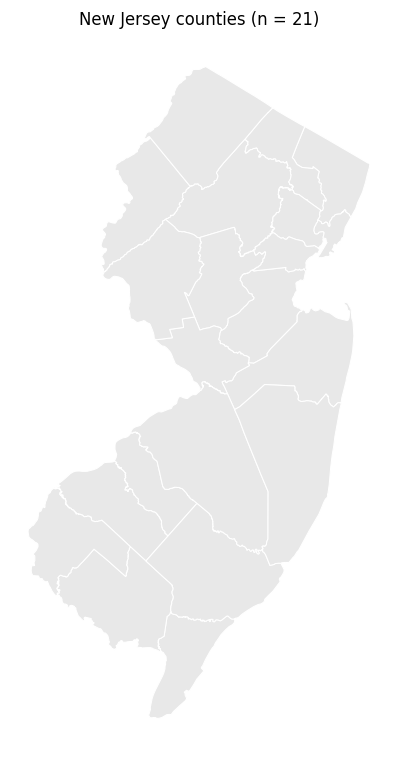

In [24]:
fig, ax = plt.subplots(figsize=(5, 7))
nj.plot(ax=ax, color="#e8e8e8", **EDGE)
ax.set_title("New Jersey counties (n = 21)")
ax.axis("off")
plt.tight_layout()
plt.show()

This is just 21 polygons. No data yet.

But one thing is already visible that caused me trouble later. The counties are very different
sizes. Burlington, Ocean and Atlantic are huge. Hudson and Union are tiny. That means every
coloured map I make will give the empty southern counties more visual weight than they deserve.
I did not think about this until Section 6.

---
## 3. First two variables, and the first surprise

My first idea was simple: find where the money is, because people with money buy tickets. I used
median household income from the Census and unemployment from BLS so I had two different sources,
which the assignment required.

In [25]:
api_key = "aea9bb4f47cebe768f8d1ba6490f4c8ecabac98d"   # free: https://api.census.gov/data/key_signup.html

acs_url = ("https://api.census.gov/data/2023/acs/acs5"
           "?get=NAME,B19013_001E,B01003_001E,B01002_001E,B25004_006E,B25001_001E"
           "&for=county:*&in=state:34"
           "&key=" + api_key)

data = requests.get(acs_url).json()
acs = pd.DataFrame(data[1:], columns=data[0])

# The 5-digit county FIPS is the key every one of my datasets shares.
acs["GEOID"] = acs["state"] + acs["county"]

acs = acs.rename(columns={"B19013_001E": "income",
                          "B01003_001E": "population",
                          "B01002_001E": "median_age",
                          "B25004_006E": "seasonal_units",
                          "B25001_001E": "total_units"})

for c in ["income", "population", "median_age", "seasonal_units", "total_units"]:
    acs[c] = pd.to_numeric(acs[c])

# Share of homes held for seasonal, recreational or occasional use.
acs["pct_seasonal"] = 100 * acs["seasonal_units"] / acs["total_units"]

acs = acs[["GEOID", "income", "population", "median_age", "pct_seasonal"]]
acs.head()

,GEOID,income,population,median_age,pct_seasonal
0,34001,76819,274704,42.2,12.477480
1,34003,123715,954717,42.1,0.204323
2,34005,105271,464226,41.7,0.303851
3,34007,86384,524042,38.8,0.234535
4,34009,88046,95236,51.4,49.679297


In [26]:
# JOIN 1
nj = nj.merge(acs, on="GEOID", how="left")

print(len(nj), "rows |", nj["income"].isna().sum(), "unmatched")

21 rows | 0 unmatched


In [27]:
bls_url = ("https://raw.githubusercontent.com/Cherif7331/gis-class-/"
           "ca65040311c854fb2b2b3f17488c66ca906d481e/nj_unemployment.csv.xlsx")

# GEOID must be read as text or the leading zero is lost and the join fails.
bls = pd.read_excel(bls_url, dtype={"GEOID": str})

# JOIN 2
nj = nj.merge(bls[["GEOID", "unemp_rate"]], on="GEOID", how="left")

print(len(nj), "rows |", nj["unemp_rate"].isna().sum(), "unmatched")

21 rows | 0 unmatched


In [28]:
# Look at the numbers before mapping them.
nj[["population", "income", "median_age", "pct_seasonal", "unemp_rate"]].describe().round(2)

,population,income,median_age,pct_seasonal,unemp_rate
count,21.00,21.00,21.00,21.00,21.00
mean,441286.38,100890.67,41.36,4.30,4.93
std,273805.65,21273.83,3.44,11.10,1.17
min,64973.00,64499.00,35.80,0.14,3.60
25%,152915.00,86411.00,39.10,0.23,4.30
50%,464226.00,99596.00,41.70,0.42,4.60
75%,643615.00,114316.00,42.70,0.76,5.40
max,954717.00,139453.00,51.40,49.68,8.30


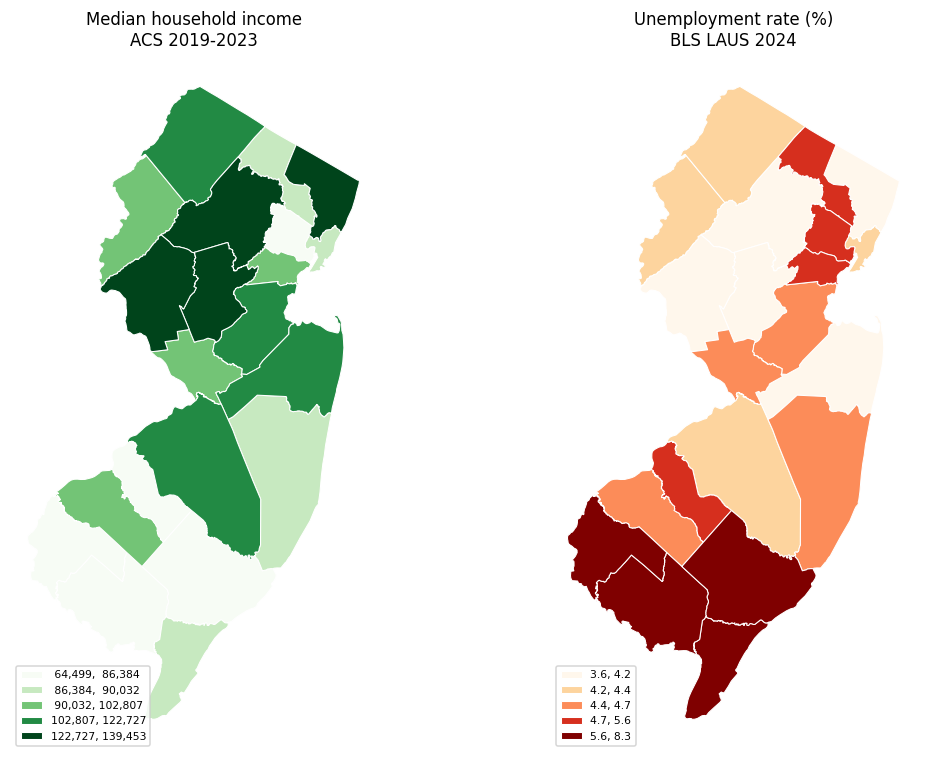

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 7))

nj.plot(column="income", ax=axes[0], cmap="Greens", scheme="quantiles", k=5,
        legend=True, legend_kwds={"loc": "lower left", "fmt": "{:,.0f}", "fontsize": 7},
        **EDGE)
axes[0].set_title("Median household income\nACS 2019-2023")
axes[0].axis("off")

nj.plot(column="unemp_rate", ax=axes[1], cmap="OrRd", scheme="quantiles", k=5,
        legend=True, legend_kwds={"loc": "lower left", "fmt": "{:.1f}", "fontsize": 7},
        **EDGE)
axes[1].set_title("Unemployment rate (%)\nBLS LAUS 2024")
axes[1].axis("off")

plt.tight_layout()
plt.show()

**What I expected, and what I got.**

I expected income to be higher near Philadelphia, since that is the part of the state I was
calling 76ers country. It is the opposite.

The money is in the north. Hunterdon, Somerset, Morris and Bergen are the top counties. All of
them are New York territory. The counties I think of as Sixers counties, Camden and Gloucester
and Salem and Cumberland, sit near the bottom. The richest county has more than double the income
of the poorest.

So the team's cultural territory and the state's money are in different places. That was not what
I set out to find and it is the first thing in this project that changed how I was thinking.

I also had to stop myself saying "South Jersey is poor," because the map does not say that.
Camden is below the state median. Gloucester, right next door, is above the mean. There is about
a 16,000 dollar gap between two counties that look identical from a fan's point of view.

The unemployment map is roughly the reverse of the income map. The useful part is where it is
not. Cape May is 8.3 percent against a state mean of 4.93. Cumberland is 7.3. Reading the two maps
together splits South Jersey into a weak group and a workable one, where Gloucester has decent
income and low unemployment. One variable on its own could not have shown me that.

I used quantile classification rather than equal intervals because both variables are skewed and
equal intervals put most of the counties in one class.

---
## 4. A question I could not answer in class

When I presented this, someone asked why Cape May looked so bad. Was it retirement? Was it
seasonal work? I did not know. I had a guess but no evidence.

So instead of guessing I went back to the Census and pulled two more variables: median age, and
the share of housing units held for seasonal or occasional use. Then I mapped them.

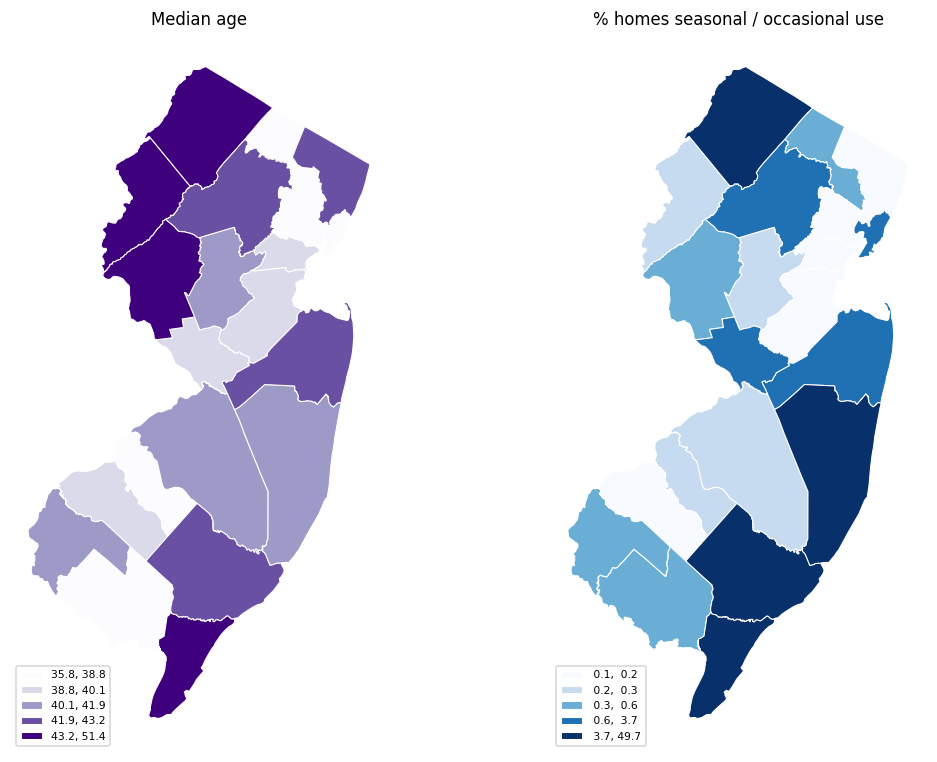

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11, 7))

nj.plot(column="median_age", ax=axes[0], cmap="Purples", scheme="quantiles", k=5,
        legend=True, legend_kwds={"loc": "lower left", "fmt": "{:.1f}", "fontsize": 7},
        **EDGE)
axes[0].set_title("Median age")
axes[0].axis("off")

nj.plot(column="pct_seasonal", ax=axes[1], cmap="Blues", scheme="quantiles", k=5,
        legend=True, legend_kwds={"loc": "lower left", "fmt": "{:.1f}", "fontsize": 7},
        **EDGE)
axes[1].set_title("% homes seasonal / occasional use")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [31]:
nj[["county", "median_age", "pct_seasonal", "unemp_rate", "income"]] \
    .sort_values("pct_seasonal", ascending=False).head(8)

,county,median_age,pct_seasonal,unemp_rate,income
2,Cape May,51.4,49.679297,8.3,88046
17,Ocean,41.4,13.902392,4.7,86411
14,Atlantic,42.2,12.477480,5.8,76819
20,Sussex,44.1,4.544369,4.4,114316
7,Monmouth,43.2,3.743030,4.2,122727
18,Hudson,35.8,0.756075,4.3,90032
8,Mercer,39.2,0.690571,4.6,96333
1,Morris,42.7,0.605203,3.8,134929


**Both guesses were right, and the numbers are not close.**

Cape May is 49.7 percent seasonal. Almost half the homes there are not lived in year round. Ocean
is next at 13.9, then Atlantic at 12.5. Every other county except Sussex is under 5 percent and
most are under 1. Cape May also has the oldest population in the state at 51.4.

That explains the 8.3 percent unemployment. The BLS figure is an annual average, so it carries
the whole off season. The county staffs for a summer population that the Census never counts,
because ACS only measures year-round residents. So my income number and my unemployment number
are describing two different groups of people in that county.

**But I checked whether seasonality explains unemployment generally, and it does not.** Ocean is
13.9 percent seasonal with 4.7 percent unemployment, which is below the state average. And
Cumberland has 7.3 percent unemployment with basically no seasonal housing at all, 0.57 percent.
It just has the lowest income in the state.

So my two darkest counties are dark for completely different reasons. Cape May is a seasonal
labour market. Cumberland is structural weakness. The choropleth gives them the same colour and
there is no way to tell them apart by looking. I knew a choropleth could hide population. I had
not thought about it hiding cause.

**Why this matters for basketball, which I did not see at first.** The NBA season runs October to
April. Cape May's summer population is irrelevant to a basketball team. Half that housing is empty
in January. So seasonality is not a side note, it is a correction to market size for a winter
sport.

One thing I got wrong and want to flag: Sussex is 4.5 percent seasonal and it is not a shore
county. It is lake country in the northwest. "Seasonal" means vacation homes in general, not
beaches.

---
## 5. Realising I was assuming my answer

At this point I noticed something about my own project. I kept writing "Philadelphia market" and
"New York market" and a "contested band" in the middle, but I had never measured any of it. I was
asserting the boundary and then mapping other things inside it.

So I went looking for data that actually defines the boundary. OMB publishes metro area
delineations built from commuting flows and population density, one row per county. That is a
measurement, not an assumption, and it comes from a different producer than Census or BLS.

In [32]:
cbsa_url = ("https://raw.githubusercontent.com/Cherif7331/gis-class-/"
            "96ac2d186c9a93de81f8a0d5462c292fb7f7f1df/"
            "OMB%20/%20Census%20CBSA%20delineation%20file.xlsx")

# This is OMB's List 1 with its own column names, so I do the cleaning here
# rather than in Excel. That way every step is visible and replicable.
cbsa_raw = pd.read_excel(cbsa_url)
print(cbsa_raw.columns.tolist())

nj_cbsa = cbsa_raw[cbsa_raw["FIPS State Code"] == 34].copy()

# Same GEOID construction as the other sources: state FIPS + 3-digit county FIPS.
nj_cbsa["GEOID"] = "34" + nj_cbsa["FIPS County Code"].astype(int).astype(str).str.zfill(3)

nj_cbsa = nj_cbsa[["GEOID", "CBSA Title", "Metropolitan Division Title"]].rename(
    columns={"CBSA Title": "cbsa_title",
             "Metropolitan Division Title": "metro_div_title"})
nj_cbsa = nj_cbsa.drop_duplicates(subset=["GEOID"])

print(len(nj_cbsa), "NJ counties in the OMB file")

['CBSA Code', 'Metropolitan Division Code', 'CSA Code', 'CBSA Title', 'Metropolitan/Micropolitan Statistical Area', 'Metropolitan Division Title', 'CSA Title', 'County/County Equivalent', 'State Name', 'FIPS State Code', 'FIPS County Code', 'Central/Outlying County']
21 NJ counties in the OMB file


In [33]:
# JOIN 3. Left join on purpose: a county in no metro area would be absent from the
# OMB file, and that absence would itself be a finding, so I keep all 21 rows.
nj = nj.merge(nj_cbsa, on="GEOID", how="left")

print(len(nj), "rows")
nj[["county", "cbsa_title", "metro_div_title"]].sort_values("cbsa_title")

21 rows


,county,cbsa_title,metro_div_title
10,Warren,"Allentown-Bethlehem-Easton, PA-NJ",NaN
2,Cape May,"Atlantic City-Hammonton, NJ",NaN
14,Atlantic,"Atlantic City-Hammonton, NJ",NaN
18,Hudson,"New York-Newark-Jersey City, NY-NJ","New York-Jersey City-White Plains, NY-NJ"
17,Ocean,"New York-Newark-Jersey City, NY-NJ","Lakewood-New Brunswick, NJ"
15,Essex,"New York-Newark-Jersey City, NY-NJ","Newark, NJ"
13,Hunterdon,"New York-Newark-Jersey City, NY-NJ","Newark, NJ"
12,Passaic,"New York-Newark-Jersey City, NY-NJ","New York-Jersey City-White Plains, NY-NJ"
11,Bergen,"New York-Newark-Jersey City, NY-NJ","New York-Jersey City-White Plains, NY-NJ"
19,Union,"New York-Newark-Jersey City, NY-NJ","Newark, NJ"


In [34]:
# Collapse seven metro areas into the three categories my question cares about.
def market(title):
    if isinstance(title, str) and title.startswith("Philadelphia"):
        return "Philadelphia"
    elif isinstance(title, str) and title.startswith("New York"):
        return "New York"
    else:
        return "Neither"

nj["market"] = nj["cbsa_title"].apply(market)
nj["market"].value_counts()

,count
market,
New York,12
Neither,5
Philadelphia,4


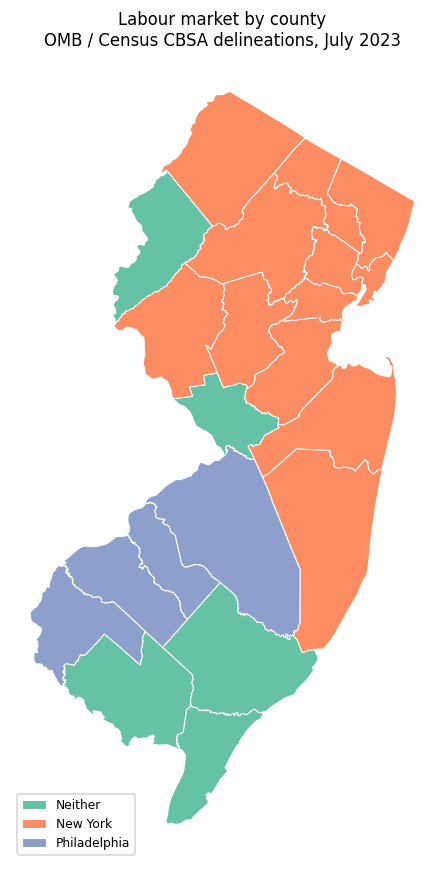

In [35]:
fig, ax = plt.subplots(figsize=(6, 8))

nj.plot(column="market", ax=ax, cmap="Set2", legend=True,
        legend_kwds={"loc": "lower left", "fontsize": 8}, **EDGE)

ax.set_title("Labour market by county\nOMB / Census CBSA delineations, July 2023")
ax.axis("off")
plt.tight_layout()
plt.show()

**I was wrong, and not by a little.**

Philadelphia's New Jersey footprint is four counties. Camden, Burlington and Gloucester are in the
Camden, NJ metropolitan division, and Salem is in the Wilmington division. That is all of it.

Twelve counties are New York-Newark-Jersey City. That includes Monmouth and Ocean, which I had
been calling contested. They are in the Lakewood-New Brunswick division. By commuting behaviour
they are not contested, they are New York.

Five counties belong to neither. Mercer is its own metro, Trenton. Cumberland is Vineland.
Atlantic and Cape May are Atlantic City-Hammonton. Warren is the odd one, because it commutes to
Allentown, which is in Pennsylvania but is not Philadelphia. So my "Neither" category is really
two different situations stuck together and I would split it if I did this again.

There is no gradient. There is a hard edge at four counties, then a buffer of self-contained local
metros, then New York. At this point I thought the independent metros were my expansion targets.
Section 7 is me finding out that is also wrong.

---
## 6. Checking whether my own maps were lying to me

Back in Section 2 I noticed the counties are wildly different sizes. Every map so far colours
area, so the big empty southern counties take up most of the ink while Hudson nearly disappears
even though a lot of people live there.

Centroids are the fix. If I put a dot at the centre of each county and size it by population, the
dots show where the people are and the fill shows the market. I compute them in UTM Zone 18N
because that is a projected system measured in metres. Taking a centroid in the raw lat-long
system would be averaging degrees, which is not a real location.

In [36]:
UTM = 32618   # UTM zone 18N, metres, covers NJ and Philadelphia

nj_utm = nj.to_crs(UTM)
nj["centroid"] = nj_utm.geometry.centroid.to_crs(nj.crs)

# Straight-line distance from each county centroid to the Sixers' arena in South Philadelphia.
ARENA_LAT, ARENA_LON = 39.9012, -75.1720
arena = gpd.GeoSeries(gpd.points_from_xy([ARENA_LON], [ARENA_LAT]), crs=4326).to_crs(UTM).iloc[0]
nj["miles_to_arena"] = (nj_utm.geometry.centroid.distance(arena) / 1609.34).round(1)

nj[["county", "market", "miles_to_arena", "population"]].sort_values("miles_to_arena").head(8)

,county,market,miles_to_arena,population
0,Gloucester,Philadelphia,12.8,304504
4,Camden,Philadelphia,13.2,524042
9,Salem,Philadelphia,23.6,64973
16,Burlington,Philadelphia,26.8,464226
8,Mercer,Neither,36.3,383286
6,Cumberland,Neither,36.5,152915
14,Atlantic,Neither,39.9,274704
17,Ocean,New York,47.3,646434


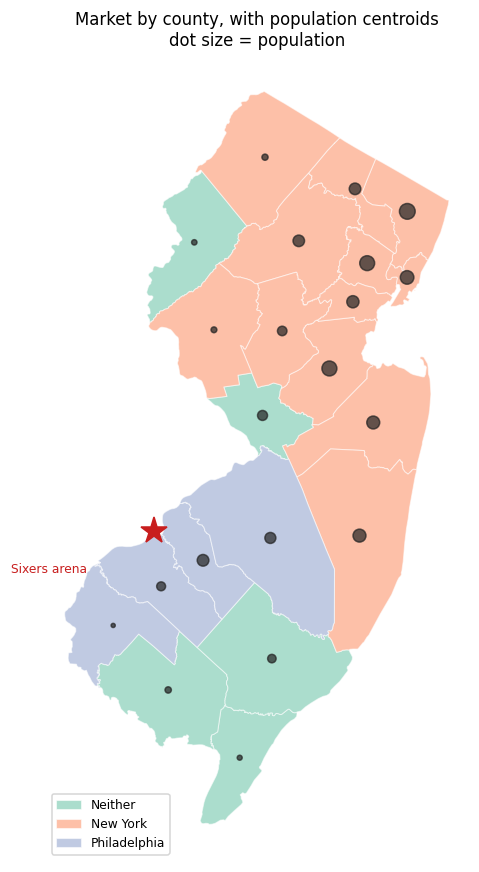

In [37]:
fig, ax = plt.subplots(figsize=(6, 8))

# Market fill underneath, population centroids on top: two geometry types overlaid.
nj.plot(column="market", ax=ax, cmap="Set2", alpha=0.55, legend=True,
        legend_kwds={"loc": "lower left", "fontsize": 8}, **EDGE)

gpd.GeoSeries(nj["centroid"], crs=nj.crs).plot(
    ax=ax, color="#222222", markersize=nj["population"] / 9000, alpha=0.7, zorder=3)

ax.plot(ARENA_LON, ARENA_LAT, marker="*", color="#c81e1e", markersize=18, zorder=5)
ax.annotate("Sixers arena", xy=(ARENA_LON, ARENA_LAT),
            xytext=(ARENA_LON - 0.62, ARENA_LAT - 0.14), fontsize=8, color="#c81e1e")

ax.set_title("Market by county, with population centroids\ndot size = population")
ax.axis("off")
plt.tight_layout()
plt.show()

The overlay makes the problem concrete. The Philadelphia wedge looks big as fill but its dots are
modest. The New York counties carry a dense cluster of large dots in the northeast that the fill
badly understates. Cape May, the darkest county on my unemployment map, has one of the smallest
dots here.

I also measured straight-line distance from each centroid to the arena. The four Philadelphia
counties are also the closest, so proximity and commuting agree and the base looks real and
compact.

Two things wrong with the distance numbers that I want to be honest about. They are straight
lines, so they ignore the Delaware River and the fact that the only way into South Philadelphia
from Camden County is over a bridge. Drive time would be much better. And the centroid is not
where people live. Ocean County's centroid is inland and its population is on the coast.

---
## 7. A second way to measure the boundary, which changed my answer

The OMB data measures commuting. But a basketball team does not sell to commuters, it sells to
television audiences. Those are not the same thing, and I had been treating them as if they were.

The proper measure is the Nielsen DMA, which is the TV market. Nielsen's own file is proprietary,
so I used a public compilation of their county assignments. I was expecting it to roughly match
the commuting map.

In [38]:
dma_url = ("https://raw.githubusercontent.com/alex-patton/US-TVDMA-BY-COUNTY/"
           "master/usa-tvdma-county.csv")

dma_raw = pd.read_csv(dma_url)
nj_dma = dma_raw[dma_raw["STATE_AB"] == "NJ"].copy()

# This file has county names, not FIPS, so I join on the name instead of GEOID.
nj_dma["county_key"] = nj_dma["COUNTY"].str.strip().str.upper()
nj_dma = nj_dma[["county_key", "TVDMA"]].rename(columns={"TVDMA": "dma"})

nj["county_key"] = nj["county"].str.upper()

# JOIN 4
nj = nj.merge(nj_dma, on="county_key", how="left")

print(len(nj), "rows |", nj["dma"].isna().sum(), "unmatched")
nj["dma"].value_counts()

21 rows | 0 unmatched


,count
dma,
"New York, NY - CT - NJ - PA DMA",13
"Philadelphia, PA - DE - NJ DMA",8


In [39]:
def dma_short(d):
    return "Philadelphia" if isinstance(d, str) and d.startswith("Philadelphia") else "New York"

nj["dma_market"] = nj["dma"].apply(dma_short)

# CBSA has a third category (Neither) that DMA does not, so this is not a
# like-for-like disagreement. It shows where TV reach exceeds commuting reach.
pd.crosstab(nj["market"], nj["dma_market"])

dma_market,New York,Philadelphia
market,,
Neither,1,4
New York,12,0
Philadelphia,0,4


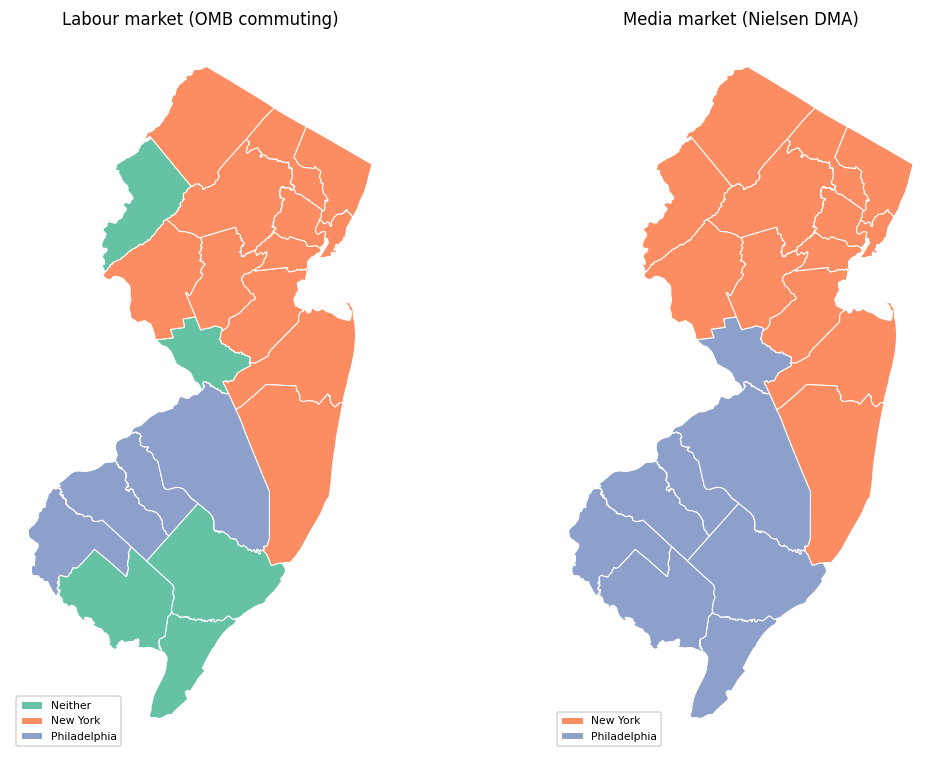

In [40]:
# Colours are fixed to the category names on purpose. The left panel has three
# categories and the right has two, so a colormap would give Philadelphia a
# different colour in each panel and the comparison would be unreadable.
COLORS = {"Philadelphia": "#8da0cb", "New York": "#fc8d62", "Neither": "#66c2a5"}

def market_panel(col, ax, title):
    for name, grp in nj.groupby(col):
        grp.plot(ax=ax, color=COLORS[name], label=name, **EDGE)
    ax.legend(loc="lower left", fontsize=7)
    ax.set_title(title)
    ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(11, 7))
market_panel("market", axes[0], "Labour market (OMB commuting)")
market_panel("dma_market", axes[1], "Media market (Nielsen DMA)")
plt.tight_layout()
plt.show()

**It does not match, and the gap is the most interesting thing I found.**

Commuting puts four New Jersey counties in Philadelphia. The TV market puts eight.

The four extra ones are Atlantic, Cape May, Cumberland and Mercer. Those are exactly the counties
my commuting map had filed under "Neither." Nobody commutes from Cape May to Philadelphia, but
they watch Philadelphia television. Media reach goes a long way past labour-market reach.

**This corrects what I wrote in Section 5.** I called those counties expansion targets. They are
not. They are already inside the market. My base is eight counties, not four.

Monmouth and Ocean are New York under both measures, so that one holds up. Warren is the only
county that disagrees the other way: Nielsen says New York, OMB says Allentown.

The two measures answer different business questions, which is why I am keeping both maps rather
than picking one. Commuting tells you where people work, which is about who can get to a weeknight
game. DMA tells you who sees the broadcast, which is about sponsorship and rights value. Eight
counties is the sponsorship market. Four is closer to the gate.

**A note on the colours.** I set them explicitly instead of letting the colormap choose. The left
panel has three categories and the right has two, so the colormap was giving Philadelphia a
different colour in each panel and it looked like the whole state had flipped. Locking the colours
to the category names fixed it.

**A warning about this data source.** It is a volunteer compilation, not an official Nielsen
release. The author says he scraped and cleaned it in a few hours, that it has not been reviewed
much for errors, and that DMAs change over time. There is no licence file and no link to an
original source. I used it because Nielsen's delineations are not public. Before I relied on this
for anything real I would check it against the Harvard Dataverse DMA dataset
(Sood, doi:10.7910/DVN/IVXEHT).

---
## 8. Where this leaves me

Starting assumption: South Jersey is Sixers country and there is a contested middle band.

What the data says instead:

- The money is in the north, in New York territory, not in Sixers country.
- The commuting market is four counties with a hard edge, not a gradual band.
- The TV market is eight counties and includes places nobody commutes from.
- Monmouth and Ocean are New York under both measures, so that part of my assumption was just
  wrong.

**The practical answer.** Gloucester, Camden and Burlington are the core. They are close, they are
in both definitions of the market, and Gloucester in particular has decent income with low
unemployment. The four counties that are TV-Philadelphia but not commute-Philadelphia are a
different kind of target, because the broadcast already reaches them but the drive does not. And
the shore counties need their market size discounted, because a chunk of their housing is empty
during basketball season.

**The biggest thing still missing.** I have no fan data. No ticket sales, no viewership, no
attendance. Everything here describes households, not fans. The New York Times mapped NBA and MLB
fandom by ZIP code using Facebook data, but it was never released in a form you can download, and
only the top three teams per area are public. So what I have is a map of the addressable market,
not of demand, and I should not claim more than that.

**Questions**

- My "Neither" category mixes self-contained metros with Warren, which commutes to Allentown. Is
  it better to split that out, or does three categories communicate more clearly?
- For the final project I would like to use spatial statistics, but 21 counties is a very small n.
  Would you move me to census tracts, or widen out to all the counties in both DMAs?
- Is there a better DMA source than the volunteer compilation I used?

---
## 9. Problems I hit

Keeping this because most of it cost me real time and I would not want to repeat it.

1. **The Census API returned HTML instead of JSON.** It looked like a parsing error. It was
   actually a missing API key, which is free, but you have to click the activation email or it
   keeps saying the key is invalid.
2. **A KeyError on `income` that was not about income.** The column was missing because the join
   cell was not in the notebook at all. I found it by running `nj.columns` instead of guessing.
3. **Stale cells.** If you change a cell near the top, everything below it is still running on old
   data until you restart and run again. This bit me twice before I understood it.
4. **A one-colour map.** The CBSA codes came in as text because the file has footnote rows at the
   bottom, so comparing them to a number was always false and every county fell into the same
   category. Using the title strings instead fixed it.
5. **Colours that did not match across a side-by-side.** Covered in Section 7.
6. **I lost my whole notebook** by not saving to GitHub before closing Colab. Had to rebuild it.
   I save a copy to GitHub every session now.

---
## Appendix: AI use disclosure

**Tools.** Claude (Anthropic) and the Gemini assistant built into Google Colab,
September and October 2026.

**What I asked for.** I gave Claude the syllabus and the PS0, PS1 and PS2 PDFs and asked it to
help me shape the notebooks clearly and organise my notes in a chronologicall form

**What the AI produced.** its in the cells the count off the issues and place them at the right spcace, also multiple errore codes through gemeni



**Other sources.** GeoPandas documentation (https://geopandas.org/), the class notebook
(https://github.com/theaok/gisPy/blob/main/map.ipynb), and the Census API documentation
(https://www.census.gov/data/developers/data-sets/acs-5year.html).